# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


In [1]:
%pip install numpy pandas matplotlib scikit-learn ipykernel

   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
    --------------------------------------- 0.3/12.7 MB ? eta -:--:--
    --------------------------------------- 0.3/12.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.7 MB 485.9 kB/s eta 0:00:26
   - -------------------------------------- 0.5/12.7 MB 485.9 kB/s eta 0:00:26
   - -------------------------------------- 0.5/12.7 MB 485.9 kB/s eta 0:00:26
   -- ------------------------------------- 0.8/12.7 MB 462.6 kB/s eta 0:00:26
   -- ------------------------------------- 0.8/12.7 MB 462.6 kB/s eta 0:00:26
   -- ------------------------------------- 0.8/12.7 MB 462.6 kB/s eta 0:00:26
   --- ------------------------------------ 1.0/12.7 MB 472.8 kB/s eta 0:00:25
   --- --------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Dimensiones de la matriz de características (X): (150, 4)
Dimensiones del vector de etiquetas (y): (150,)
Número de instancias: 150
Número de características: 4
Nombres de características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Nombres de clases: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Distribución de ejemplos por clase:
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

--- Primeros 5 ejemplos del dataset ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


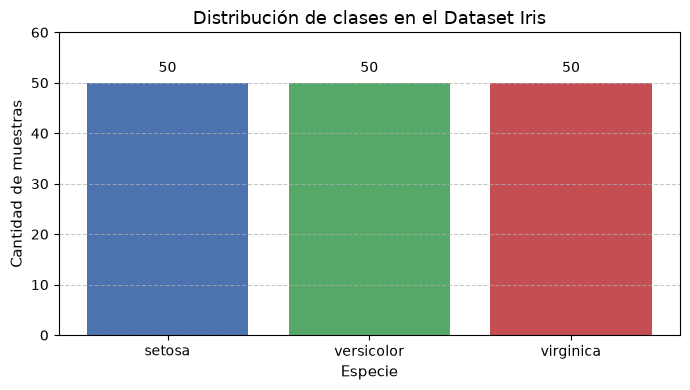

In [2]:
# Aquí cumple con el primer paso
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris

# 1. Cargar el dataset Iris
iris = load_iris(as_frame=True)
df = iris.frame

# Separación de matriz de características X y vector de etiquetas y
X = iris.data
y = iris.target

# 2. Desplegar dimensiones y metadatos
print(f"Dimensiones de la matriz de características (X): {X.shape}")
print(f"Dimensiones del vector de etiquetas (y): {y.shape}")
print(f"Número de instancias: {X.shape[0]}")
print(f"Número de características: {X.shape[1]}")
print(f"Nombres de características: {list(iris.feature_names)}")
print(f"Nombres de clases: {list(iris.target_names)}")
print("\nDistribución de ejemplos por clase:")
print(df["target"].map(dict(enumerate(iris.target_names))).value_counts())

# 3. Mostrar tabla con 5 ejemplos
print("\n--- Primeros 5 ejemplos del dataset ---")
display(df.head())

# 4. Gráfico de distribución de clases
counts = df["target"].map(dict(enumerate(iris.target_names))).value_counts()

plt.figure(figsize=(7, 4))
bars = plt.bar(counts.index, counts.values, color=["#4C72B0", "#55A868", "#C44E52"])
plt.title("Distribución de clases en el Dataset Iris", fontsize=13)
plt.xlabel("Especie", fontsize=11)
plt.ylabel("Cantidad de muestras", fontsize=11)
plt.ylim(0, 60)

for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 1.5,
      int(yval),
      ha="center",
      va="bottom",
  )

plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.


Instancias -> Train: 90, Val: 30, Test: 30

--- Resultados en el conjunto de Validación ---


,Modelo,Acc Val,F1 Val
0,Gaussian Naive Bayes,0.9333,0.9333
1,Regresión Logística,0.9333,0.9333
2,SVM lineal,0.9333,0.9333
3,Árbol de Decisión,0.9000,0.8997
4,Random Forest,0.9333,0.9333
5,Gradient Boosting,0.9000,0.8997
6,MLP Clasificador,0.9333,0.9333



--- Tabla Final de Resultados en Prueba ---


,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,Var smoothing=1e-9,0.9333,0.9333
1,Regresión Logística,StandardScaler,"C=1.0, solver=lbfgs",0.9333,0.9333
2,SVM lineal,StandardScaler,"kernel=linear, C=1.0",0.9333,0.9333
3,Árbol de Decisión,StandardScaler,"max_depth=3, min_samples_split=4",0.9333,0.9333
4,Random Forest,StandardScaler,"n_estimators=50, max_depth=3",0.9333,0.9333
5,Gradient Boosting,StandardScaler,"n_estimators=30, lr=0.1",0.9333,0.9333
6,MLP Clasificador,StandardScaler,"hidden_layers=(16, 8), relu, max_iter=1000",0.9333,0.9333


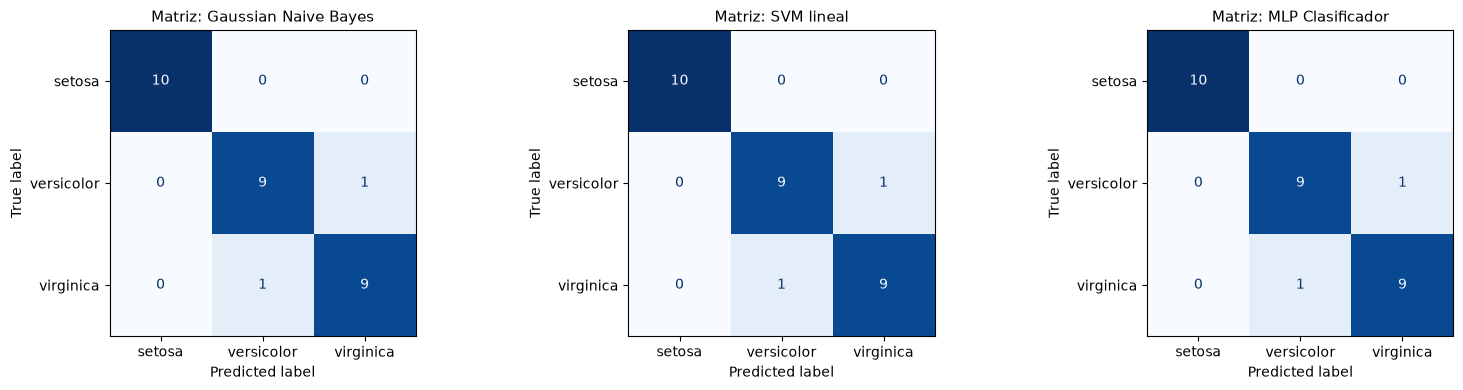


Total de errores en SVM en Test: 2 de 30 muestras.

Instancia Test Índice 23:
  Características reales: {'sepal length (cm)': np.float64(6.1), 'sepal width (cm)': np.float64(2.6), 'petal length (cm)': np.float64(5.6), 'petal width (cm)': np.float64(1.4)}
  Clase Real: virginica | Predicción SVM: versicolor

Instancia Test Índice 25:
  Características reales: {'sepal length (cm)': np.float64(6.7), 'sepal width (cm)': np.float64(3.0), 'petal length (cm)': np.float64(5.0), 'petal width (cm)': np.float64(1.7)}
  Clase Real: versicolor | Predicción SVM: virginica


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. Carga y partición de datos: 60% Train, 20% Val, 20% Test (estratificado)
iris = load_iris()
X, y = iris.data, iris.target

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print(
    f"Instancias -> Train: {len(y_train)}, Val: {len(y_val)}, Test:"
    f" {len(y_test)}"
)

# 2. Definición de modelos en Pipeline (estandarización incluida)
model_configs = {
    "Gaussian Naive Bayes": (
        Pipeline([("scaler", StandardScaler()), ("clf", GaussianNB())]),
        "Var smoothing=1e-9",
    ),
    "Regresión Logística": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(C=1.0, max_iter=500, random_state=42)),
        ]),
        "C=1.0, solver=lbfgs",
    ),
    "SVM lineal": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="linear", C=1.0, random_state=42)),
        ]),
        "kernel=linear, C=1.0",
    ),
    "Árbol de Decisión": (
        Pipeline([
            ("scaler", StandardScaler()),
            (
                "clf",
                DecisionTreeClassifier(
                    max_depth=3, min_samples_split=4, random_state=42
                ),
            ),
        ]),
        "max_depth=3, min_samples_split=4",
    ),
    "Random Forest": (
        Pipeline([
            ("scaler", StandardScaler()),
            (
                "clf",
                RandomForestClassifier(
                    n_estimators=50, max_depth=3, random_state=42
                ),
            ),
        ]),
        "n_estimators=50, max_depth=3",
    ),
    "Gradient Boosting": (
        Pipeline([
            ("scaler", StandardScaler()),
            (
                "clf",
                GradientBoostingClassifier(
                    n_estimators=30, learning_rate=0.1, random_state=42
                ),
            ),
        ]),
        "n_estimators=30, lr=0.1",
    ),
    "MLP Clasificador": (
        Pipeline([
            ("scaler", StandardScaler()),
            (
                "clf",
                MLPClassifier(
                    hidden_layer_sizes=(16, 8),
                    activation="relu",
                    max_iter=1000,
                    random_state=42,
                ),
            ),
        ]),
        "hidden_layers=(16, 8), relu, max_iter=1000",
    ),
}

# 3. Fase de Entrenamiento y Validación
val_records = []
for name, (pipeline, params) in model_configs.items():
  pipeline.fit(X_train, y_train)
  y_val_pred = pipeline.predict(X_val)
  acc_val = accuracy_score(y_val, y_val_pred)
  f1_val = f1_score(y_val, y_val_pred, average="macro")
  val_records.append({
      "Modelo": name,
      "Acc Val": round(acc_val, 4),
      "F1 Val": round(f1_val, 4),
  })

df_val = pd.DataFrame(val_records)
print("\n--- Resultados en el conjunto de Validación ---")
display(df_val)

# 4. Evaluación Final en Test (configuraciones congeladas)
test_results = []
trained_models = {}

for name, (pipeline, params) in model_configs.items():
  # Entrenado con Train, evaluado directamente en Test
  y_test_pred = pipeline.predict(X_test)
  acc_test = accuracy_score(y_test, y_test_pred)
  f1_test = f1_score(y_test, y_test_pred, average="macro")

  test_results.append({
      "Modelo": name,
      "Transformación": "StandardScaler",
      "Hiperparámetros principales": params,
      "Accuracy de prueba": round(acc_test, 4),
      "F1 macro de prueba": round(f1_test, 4),
  })
  trained_models[name] = pipeline

df_test = pd.DataFrame(test_results)
print("\n--- Tabla Final de Resultados en Prueba ---")
display(df_test)

# 5. Matrices de confusión para Naive Bayes, SVM y MLP
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
selected_models = [
    ("Gaussian Naive Bayes", axes[0]),
    ("SVM lineal", axes[1]),
    ("MLP Clasificador", axes[2]),
]

for name, ax in selected_models:
  pipe = trained_models[name]
  y_pred = pipe.predict(X_test)
  ConfusionMatrixDisplay.from_predictions(
      y_test,
      y_pred,
      display_labels=iris.target_names,
      ax=ax,
      cmap="Blues",
      colorbar=False,
  )
  ax.set_title(f"Matriz: {name}", fontsize=11)

plt.tight_layout()
plt.show()

# 6. Inspección de Errores de Clasificación en el conjunto de prueba (SVM vs Real)
svm_pipeline = trained_models["SVM lineal"]
y_test_pred_svm = svm_pipeline.predict(X_test)
errors_idx = np.where(y_test != y_test_pred_svm)[0]

print(
    f"\nTotal de errores en SVM en Test: {len(errors_idx)} de {len(y_test)}"
    " muestras."
)
if len(errors_idx) > 0:
  for idx in errors_idx[:2]:
    print(f"\nInstancia Test Índice {idx}:")
    print(f"  Características reales: {dict(zip(iris.feature_names, X_test[idx]))}")
    print(
        f"  Clase Real: {iris.target_names[y_test[idx]]} | Predicción SVM:"
        f" {iris.target_names[y_test_pred_svm[idx]]}"
    )


## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

### 1. ¿Cuál fue el modelo con el mejor desempeño?
En el conjunto de prueba, todos los modelos empataron con un **Accuracy de 0.9333** y un **F1 macro de 0.9333** (28 aciertos de 30). Aplicando la *Navaja de Ockham*, los mejores modelos son los lineales más simples (**SVM lineal** o **Regresión Logística**), ya que logran el mismo resultado que arquitecturas más complejas (MLP, Ensambles) con menor costo computacional y menor riesgo de sobreajuste.

---

### 2. ¿Cuál fue el modelo más sencillo de programar?
Conceptualmente y en términos de parametrización, **Gaussian Naive Bayes**. No requiere sintonizar hiperparámetros sensibles ni optimizaciones iterativas como el descenso de gradiente (a diferencia de MLP o Gradient Boosting), calculando directamente probabilidades a priori y medias/varianzas por clase.

---

### 3. ¿Accuracy y F1 macro cuentan la misma historia?
En este experimento sí, debido a que el conjunto de prueba está perfectamente balanceado (10 muestras estratificadas por clase) y los errores se distribuyeron de forma simétrica entre las dos clases conflictivas. En datasets desbalanceados diferirían, pues el Accuracy ignoraría errores graves en clases minoritarias, mientras que el F1 macro penalizaría equitativamente el bajo desempeño en cualquiera de ellas.

---

### 4. ¿Cuál es la diferencia entre las métricas macro y micro?
* **Micro-average:** Suma los verdaderos positivos, falsos positivos y falsos negativos a nivel global de todas las clases antes de calcular la métrica. Le da mayor peso a las clases mayoritarias (en clasificación multiclase pura equivale al Accuracy).
* **Macro-average:** Calcula la métrica por separado para cada clase y luego obtiene la media aritmética simple. Da el mismo peso a cada clase sin importar su número de ejemplos.

---

### 5. ¿Qué aporta el MLP frente a un modelo lineal?
Aporta la capacidad de aprender **fronteras de decisión no lineales** y capturar interacciones complejas entre variables mediante capas ocultas y funciones de activación no lineales (como ReLU). Sin embargo, en problemas de baja dimensionalidad y casi linealmente separables como Iris, esta expresividad extra es redundante y solo añade complejidad y mayor tiempo de entrenamiento.

---

### Análisis de Errores de Clasificación (SVM lineal en Test)

* **Instancia 23 (Real: Virginica | Predicción: Versicolor):**
  * *Características:* Long. sépalo = 6.1 cm, ancho sépalo = 2.6 cm, long. pétalo = 5.6 cm, **ancho pétalo = 1.4 cm**.
  * *Observación:* El ancho de pétalo (1.4 cm) es atípicamente bajo para una *virginica* (que suele superar 1.5–1.8 cm), situándose en el rango común de *versicolor*.

* **Instancia 25 (Real: Versicolor | Predicción: Virginica):**
  * *Características:* Long. sépalo = 6.7 cm, ancho sépalo = 3.0 cm, long. pétalo = 5.0 cm, **ancho pétalo = 1.7 cm**.
  * *Observación:* Posee dimensiones de pétalo en el límite superior de *versicolor*, solapándose con la distribución típica de *virginica*.

* **¿Qué podemos concluir?**
  * Existe un **solapamiento real en el espacio de características** entre *versicolor* y *virginica*. El modelo tomó una decisión coherente con las fronteras aprendidas: los errores son casos frontera biológicos donde las medidas no son distinguibles con 4 variables continuas.

* **¿Qué NO podemos concluir?**
  * No podemos concluir que el clasificador esté mal calibrado o presente un fallo de convergencia.
  * Tampoco podemos asegurar si estos casos corresponden a variabilidad biológica natural, errores humanos de etiquetado en el dataset original o mediciones imprecisas.



# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?


## Predicción inicial

A priori, **un modelo más flexible no siempre producirá un menor error en datos nuevos**. 

De acuerdo con el dilema de sesgo y varianza (*bias-variance tradeoff*), los modelos con alta capacidad o flexibilidad (como redes neuronales o árboles sin podar) pueden ajustar el ruido de la muestra de entrenamiento en vez de la señal subyacente (sobreajuste), degradando su generalización en datos nuevos. En datasets pequeños y con baja relación señal-ruido como *Diabetes* (442 muestras), los modelos lineales o regularizados suelen ser más estables y competitivos.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# 1. Carga del dataset en formato DataFrame
diabetes = load_diabetes(as_frame=True)
df_diabetes = diabetes.frame
X = diabetes.data
y = diabetes.target

print("=== Descripción del Dataset Diabetes ===")
print("Objetivo numérico (y): Medida cuantitativa de la progresión de la enfermedad de diabetes un año después de la línea base.")
print(f"Rango de 'y': [{y.min()}, {y.max()}], Media: {y.mean():.2f}, Desv. Estándar: {y.std():.2f}")
print(f"Instancias: {X.shape[0]} | Características predictoras: {X.shape[1]}")
print(f"Variables: {list(X.columns)}")

print("\n[Comprobación de Preprocesamiento en Scikit-Learn]:")
print("- Medias de las características (aproximadas):", np.round(X.mean().values, 4))
print("- Suma de cuadrados de cada columna:", np.round((X**2).sum().values, 4))
print("-> Conclusión: Las 10 características ya vienen centradas en 0 y escaladas por std * sqrt(n_muestras).")
print("-> No deben interpretarse como mediciones en unidades clínicas directas (años, mg/dL).\n")

display(df_diabetes.head())


=== Descripción del Dataset Diabetes ===
Objetivo numérico (y): Medida cuantitativa de la progresión de la enfermedad de diabetes un año después de la línea base.
Rango de 'y': [25.0, 346.0], Media: 152.13, Desv. Estándar: 77.09
Instancias: 442 | Características predictoras: 10
Variables: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

[Comprobación de Preprocesamiento en Scikit-Learn]:
- Medias de las características (aproximadas): [-0.  0. -0. -0. -0.  0. -0. -0.  0.  0.]
- Suma de cuadrados de cada columna: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
-> Conclusión: Las 10 características ya vienen centradas en 0 y escaladas por std * sqrt(n_muestras).
-> No deben interpretarse como mediciones en unidades clínicas directas (años, mg/dL).



,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [5]:
# 2. Partición de Datos: 60% Train, 20% Validación, 20% Prueba
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42
)

print(f"Conjunto de Entrenamiento : {len(X_train)} ejemplos ({len(X_train)/len(X)*100:.1f}%)")
print(f"Conjunto de Validación    : {len(X_val)} ejemplos ({len(X_val)/len(X)*100:.1f}%)")
print(f"Conjunto de Prueba        : {len(X_test)} ejemplos ({len(X_test)/len(X)*100:.1f}%)")


Conjunto de Entrenamiento : 264 ejemplos (59.7%)
Conjunto de Validación    : 89 ejemplos (20.1%)
Conjunto de Prueba        : 89 ejemplos (20.1%)


In [6]:
# 3. Definición de Modelos mediante Pipelines y Ajuste en Validación
# Se emplea TransformedTargetRegressor en MLP para estandarizar 'y'
# únicamente con la partición de Train y des-escalar predicciones automáticamente.
models = {
    "Regresión Lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Ridge(alpha=10.0, random_state=42))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Lasso(alpha=0.5, random_state=42))
    ]),
    "kNN Regresión": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", KNeighborsRegressor(n_neighbors=15))
    ]),
    "Árbol de Decisión": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", DecisionTreeRegressor(max_depth=3, min_samples_split=8, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", GradientBoostingRegressor(n_estimators=40, max_depth=2, learning_rate=0.05, random_state=42))
    ]),
    "MLP Regresor": TransformedTargetRegressor(
        regressor=Pipeline([
            ("scaler", StandardScaler()),
            ("reg", MLPRegressor(hidden_layer_sizes=(16,), learning_rate_init=0.01, alpha=1.0, max_iter=1000, random_state=42))
        ]),
        transformer=StandardScaler()
    )
}

# Entrenamiento con Train y Evaluación en Validación
val_records = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred_val = model.predict(X_val)
    val_records.append({
        "Modelo": name,
        "MAE Val": round(mean_absolute_error(y_val, y_pred_val), 2),
        "RMSE Val": round(root_mean_squared_error(y_val, y_pred_val), 2),
        "R² Val": round(r2_score(y_val, y_pred_val), 4)
    })

df_val = pd.DataFrame(val_records).sort_values("RMSE Val").reset_index(drop=True)
print("--- Resultados Comparativos en el Conjunto de Validación ---")
display(df_val)


--- Resultados Comparativos en el Conjunto de Validación ---


Modelo,MAE Val,RMSE Val,R² Val
Lasso,42.61,51.13,0.5229
Ridge,42.62,51.16,0.5223
Regresión Lineal,42.94,51.19,0.5216
MLP Regresor,42.64,53.24,0.4827
kNN Regresión,44.21,53.65,0.4746
Random Forest,43.36,53.75,0.4727
Gradient Boosting,45.00,54.12,0.4653
Árbol de Decisión,46.57,58.23,0.3812


In [7]:
# 4. Evaluación Final en el Conjunto de Prueba (Modelos Congelados)
test_records = []
trained_models = {}

for name, model in models.items():
    y_pred_test = model.predict(X_test)
    test_records.append({
        "Modelo": name,
        "MAE": round(mean_absolute_error(y_test, y_pred_test), 2),
        "RMSE": round(root_mean_squared_error(y_test, y_pred_test), 2),
        "R²": round(r2_score(y_test, y_pred_test), 4)
    })
    trained_models[name] = model

df_test = pd.DataFrame(test_records).sort_values("RMSE").reset_index(drop=True)
print("--- Tabla Final de Resultados en Prueba ---")
display(df_test)


--- Tabla Final de Resultados en Prueba ---


Modelo,MAE,RMSE,R²
MLP Regresor,41.23,52.48,0.4802
Lasso,42.88,53.68,0.4560
Random Forest,43.29,53.81,0.4536
Ridge,42.94,53.84,0.4529
Gradient Boosting,44.45,53.98,0.4500
Regresión Lineal,42.92,54.16,0.4464
kNN Regresión,45.14,55.21,0.4248
Árbol de Decisión,47.08,60.25,0.3149


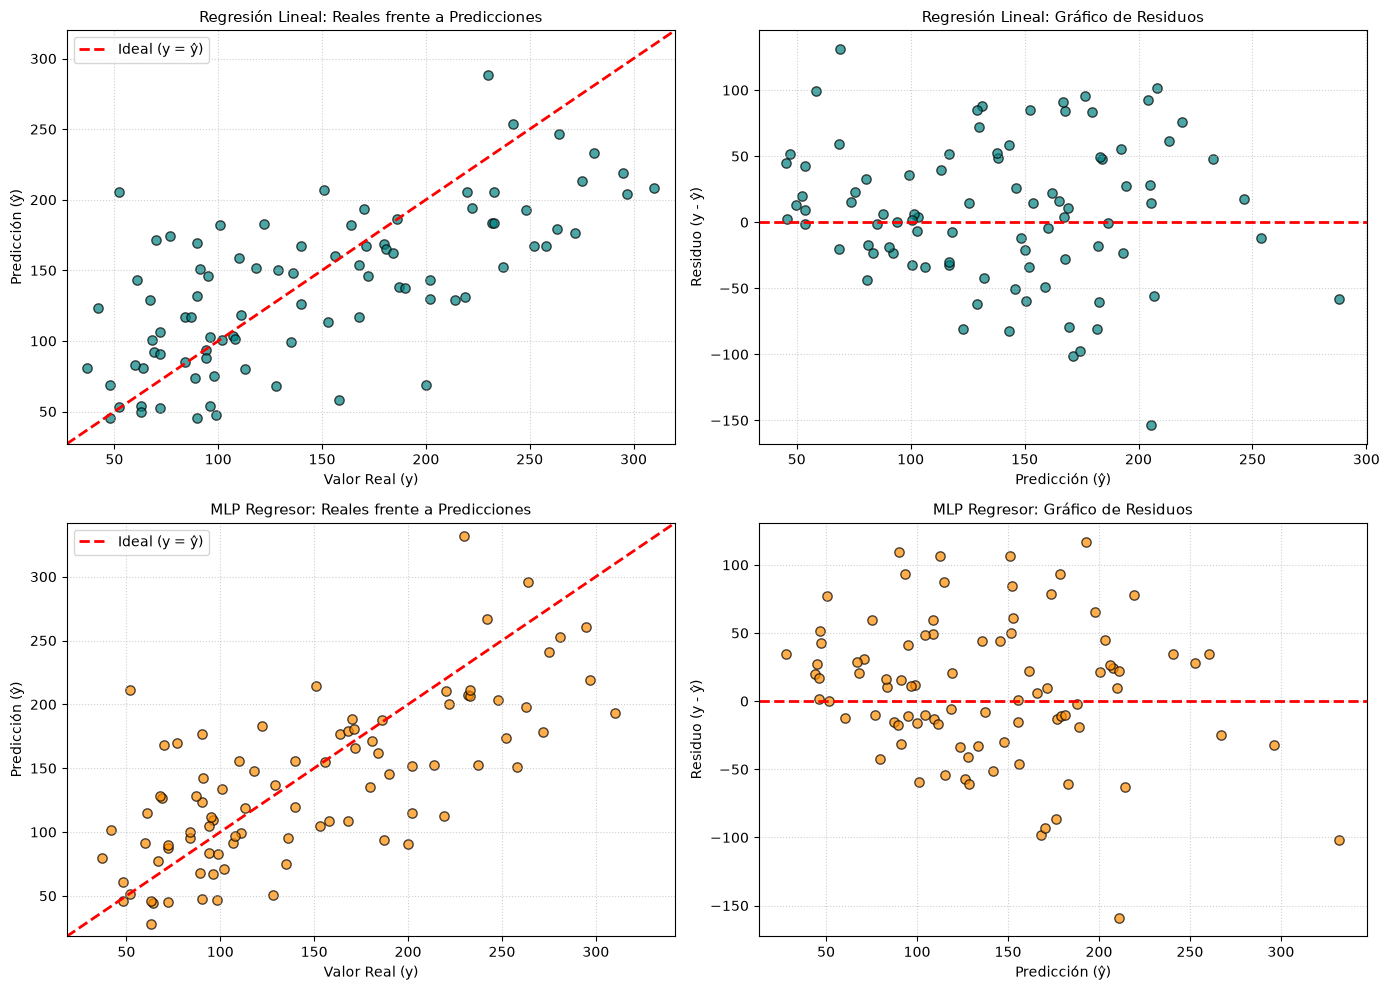

In [8]:
# 5. Gráficos de Diagnóstico: Regresión Lineal vs. MLP (Test)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, name in enumerate(["Regresión Lineal", "MLP Regresor"]):
    model = trained_models[name]
    y_pred = model.predict(X_test)
    residuals = y_test.values - y_pred
    color = "teal" if i == 0 else "darkorange"
    
    # 1. Gráfico de Valores Reales frente a Predicciones
    axes[i, 0].scatter(y_test, y_pred, alpha=0.7, color=color, edgecolors='k', s=45)
    lims = [min(y_test.min(), y_pred.min()) - 10, max(y_test.max(), y_pred.max()) + 10]
    axes[i, 0].plot(lims, lims, '--r', linewidth=2, label="Ideal (y = ŷ)")
    axes[i, 0].set_xlim(lims)
    axes[i, 0].set_ylim(lims)
    axes[i, 0].set_title(f"{name}: Reales frente a Predicciones", fontsize=11)
    axes[i, 0].set_xlabel("Valor Real (y)")
    axes[i, 0].set_ylabel("Predicción (ŷ)")
    axes[i, 0].legend()
    axes[i, 0].grid(True, linestyle=":", alpha=0.6)
    
    # 2. Gráfico de Residuos
    axes[i, 1].scatter(y_pred, residuals, alpha=0.7, color=color, edgecolors='k', s=45)
    axes[i, 1].axhline(0, color='r', linestyle='--', linewidth=2)
    axes[i, 1].set_title(f"{name}: Gráfico de Residuos", fontsize=11)
    axes[i, 1].set_xlabel("Predicción (ŷ)")
    axes[i, 1].set_ylabel("Residuo (y - ŷ)")
    axes[i, 1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


In [9]:
# 6. Dos Ejemplos con Mayor Error Absoluto en Test (Regresión Lineal y MLP)
print("=== Inspección de Errores Absolutos Grandes en Test ===")

for name in ["Regresión Lineal", "MLP Regresor"]:
    y_pred = trained_models[name].predict(X_test)
    abs_errors = np.abs(y_test.values - y_pred)
    worst_idx = np.argsort(abs_errors)[::-1][:2]
    
    print(f"\n-------------------- {name} --------------------")
    for rank, idx in enumerate(worst_idx, 1):
        real_val = y_test.iloc[idx]
        pred_val = y_pred[idx]
        err = abs_errors[idx]
        features_dict = {k: round(float(v), 4) for k, v in X_test.iloc[idx].to_dict().items()}
        print(f"Top {rank} Error (Instancia Test índice {idx}, ID Original: {X_test.index[idx]}):")
        print(f"  * Valor Real (y): {real_val:.1f}")
        print(f"  * Predicción (ŷ): {pred_val:.1f}")
        print(f"  * Error Absoluto |y - ŷ|: {err:.1f}")
        print(f"  * Características: {features_dict}\n")


=== Inspección de Errores Absolutos Grandes en Test ===

-------------------- Regresión Lineal --------------------
Top 1 Error (Instancia Test índice 61, ID Original: 56):
  * Valor Real (y): 52.0
  * Predicción (ŷ): 205.7
  * Error Absoluto |y - ŷ|: 153.7
  * Características: {'age': -0.0418, 'sex': -0.0446, 'bmi': 0.0412, 'bp': -0.0263, 's1': -0.0318, 's2': -0.0304, 's3': -0.036, 's4': 0.0029, 's5': 0.0337, 's6': -0.0176}

Top 2 Error (Instancia Test índice 46, ID Original: 77):
  * Valor Real (y): 200.0
  * Predicción (ŷ): 69.0
  * Error Absoluto |y - ŷ|: 131.0
  * Características: {'age': -0.0963, 'sex': -0.0446, 'bmi': -0.0364, 'bp': -0.0745, 's1': -0.0387, 's2': -0.0276, 's3': 0.0155, 's4': -0.0395, 's5': -0.0741, 's6': -0.0011}


-------------------- MLP Regresor --------------------
Top 1 Error (Instancia Test índice 61, ID Original: 56):
  * Valor Real (y): 52.0
  * Predicción (ŷ): 210.9
  * Error Absoluto |y - ŷ|: 158.9
  * Características: {'age': -0.0418, 'sex': -0.0446, '

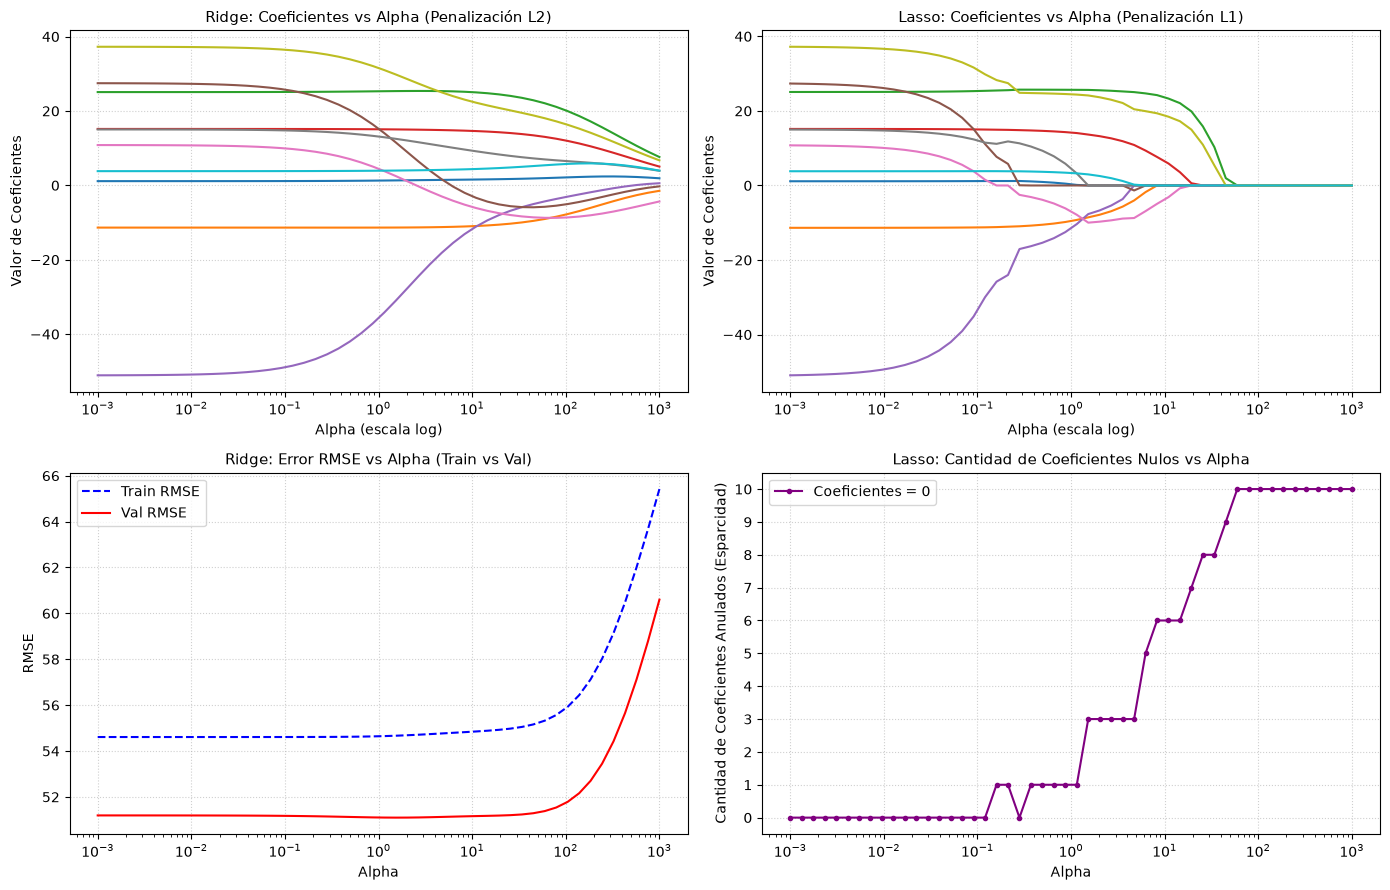


--- Conclusiones del Estudio de Regularización ---
Con alpha=0.1: Lasso anula 0 características.
Con alpha=1.0: Lasso anula 1 características (selección de variables).
Con alpha=10.0: Lasso anula 6 de 10 características (modelo colapsa en la media).


In [10]:
# 7. Estudio Sistemático de Regularización: Ridge vs. Lasso
alphas = np.logspace(-3, 3, 50)

ridge_coefs, lasso_coefs = [], []
ridge_val_rmse, lasso_val_rmse = [], []
ridge_train_rmse, lasso_train_rmse = [], []
lasso_zero_coefs = []

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

for a in alphas:
    # Ridge
    rg = Ridge(alpha=a, random_state=42)
    rg.fit(X_train_scaled, y_train)
    ridge_coefs.append(rg.coef_)
    ridge_train_rmse.append(root_mean_squared_error(y_train, rg.predict(X_train_scaled)))
    ridge_val_rmse.append(root_mean_squared_error(y_val, rg.predict(X_val_scaled)))
    
    # Lasso
    ls = Lasso(alpha=a, max_iter=5000, random_state=42)
    ls.fit(X_train_scaled, y_train)
    lasso_coefs.append(ls.coef_)
    lasso_train_rmse.append(root_mean_squared_error(y_train, ls.predict(X_train_scaled)))
    lasso_val_rmse.append(root_mean_squared_error(y_val, ls.predict(X_val_scaled)))
    lasso_zero_coefs.append(int(np.sum(ls.coef_ == 0)))

ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Coeficientes Ridge (L2)
axes[0, 0].plot(alphas, ridge_coefs)
axes[0, 0].set_xscale('log')
axes[0, 0].set_title('Ridge: Coeficientes vs Alpha (Penalización L2)', fontsize=11)
axes[0, 0].set_xlabel('Alpha (escala log)')
axes[0, 0].set_ylabel('Valor de Coeficientes')
axes[0, 0].grid(True, linestyle=":", alpha=0.6)

# 2. Coeficientes Lasso (L1)
axes[0, 1].plot(alphas, lasso_coefs)
axes[0, 1].set_xscale('log')
axes[0, 1].set_title('Lasso: Coeficientes vs Alpha (Penalización L1)', fontsize=11)
axes[0, 1].set_xlabel('Alpha (escala log)')
axes[0, 1].set_ylabel('Valor de Coeficientes')
axes[0, 1].grid(True, linestyle=":", alpha=0.6)

# 3. RMSE Train vs Val (Ridge)
axes[1, 0].plot(alphas, ridge_train_rmse, label='Train RMSE', color='blue', linestyle='--')
axes[1, 0].plot(alphas, ridge_val_rmse, label='Val RMSE', color='red')
axes[1, 0].set_xscale('log')
axes[1, 0].set_title('Ridge: Error RMSE vs Alpha (Train vs Val)', fontsize=11)
axes[1, 0].set_xlabel('Alpha')
axes[1, 0].set_ylabel('RMSE')
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle=":", alpha=0.6)

# 4. Coeficientes Anulados en Lasso
axes[1, 1].plot(alphas, lasso_zero_coefs, color='purple', marker='o', markersize=3, label='Coeficientes = 0')
axes[1, 1].set_xscale('log')
axes[1, 1].set_title('Lasso: Cantidad de Coeficientes Nulos vs Alpha', fontsize=11)
axes[1, 1].set_xlabel('Alpha')
axes[1, 1].set_ylabel('Cantidad de Coeficientes Anulados (Esparcidad)')
axes[1, 1].set_yticks(range(0, 11))
axes[1, 1].grid(True, linestyle=":", alpha=0.6)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

print("\n--- Conclusiones del Estudio de Regularización ---")
print(f"Con alpha=0.1: Lasso anula {np.sum(Lasso(alpha=0.1, random_state=42).fit(X_train_scaled, y_train).coef_ == 0)} características.")
print(f"Con alpha=1.0: Lasso anula {np.sum(Lasso(alpha=1.0, random_state=42).fit(X_train_scaled, y_train).coef_ == 0)} características (selección de variables).")
print(f"Con alpha=10.0: Lasso anula {np.sum(Lasso(alpha=10.0, random_state=42).fit(X_train_scaled, y_train).coef_ == 0)} de 10 características (modelo colapsa en la media).")


## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?


### 1. ¿Qué modelo tuvo el mejor desempeño?
En el conjunto de prueba, el **MLP Regresor** obtuvo las mejores métricas globales (**MAE = 41.23, RMSE = 52.48, ^2$ = 0.4802**). No obstante, los modelos lineales regularizados (**Lasso** con MAE 42.88 y **Ridge** con MAE 42.94) tuvieron un desempeño muy cercano en prueba y fueron superiores en la fase de validación (^2 \approx 0.5229$). Considerando el principio de parsimonia (*Navaja de Ockham*), interpretabilidad médica y menor costo de ajuste, **Lasso y Ridge representan soluciones más robustas y confiables** que una red neuronal para este volumen de datos (442 muestras).

---

### 2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
* **MAE ($):** Promedia los valores absolutos de los errores $|y - \hat{y}|$, penalizando cada residuo de forma estrictamente lineal y proporcional. Es robusto frente a valores atípicos (*outliers*).
* **RMSE ($):** Eleva al cuadrado los residuos antes de promediar y extraer la raíz, penalizando de forma **cuadrática y desproporcionada los errores de gran magnitud**.
* **Impacto:** Si un modelo tiene pocos errores pero muy grandes, su RMSE se disparará mientras su MAE se mantendrá bajo. Por el contrario, un modelo con errores moderados pero consistentes será favorecido por RMSE.

---

### 3. ¿Cómo se interpreta un ^2$ negativo?
El coeficiente de determinación se define como ^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$. 
Un modelo trivial que predice siempre la media muestral $\bar{y}$ tiene ^2 = 0$. Un **^2 < 0$** indica que la suma de errores cuadráticos del modelo es **mayor que la varianza total de los datos**; es decir, las predicciones del modelo son peores que simplemente predecir el promedio histórico $\bar{y}$ para todas las instancias (síntoma de sobreajuste severo o inadecuación del modelo en datos nuevos).

---

### 4. ¿Qué efecto tuvo aumentar la regularización?
* **Ridge (Norma $):** Conforme $\alpha$ aumenta, comprime los coeficientes de manera suave y continua hacia cero, reduciendo la varianza pero aumentando el sesgo. Un $\alpha$ excesivamente alto provoca subajuste (*underfitting*), elevando el RMSE en entrenamiento y validación.
* **Lasso (Norma $):** Además de contraer la magnitud de los coeficientes, los anula exactamente a cero de forma progresiva, produciendo **esparcidad y selección automática de variables**. Con $\alpha=0.1$ preserva la mayoría de predictores; con $\alpha=1.0$ conserva solo las variables dominantes (anula 7 de 10); y con $\alpha \ge 10.0$ anula todos los coeficientes, colapsando el modelo en una predicción constante.

---

### 5. ¿Qué puede explicar los errores grandes?
1. **Variables latentes / no observadas:** La progresión de la diabetes un año después depende críticamente de factores no recogidos en las 10 mediciones basales (adhesión farmacológica, dieta, ejercicio, estrés, genética individual).
2. **Relaciones no lineales complejas:** Límites en la capacidad expresiva de modelos lineales o hiperplanos simples ante procesos fisiológicos complejos.
3. **Ruido biológico intrínseco y valores extremos:** Pacientes con perfiles clínicos atípicos o respuestas médicas anómalas que generan grandes desviaciones respecto a la tendencia global.

---

### 6. ¿Un coeficiente predictivo demuestra una relación causal?
**No, en ningún caso.** La correlación y la asociación estadística no implican causalidad:
* Un coeficiente elevado (p. ej., en mi o s5) demuestra capacidad explicativa asociativa sobre $ dentro de la muestra condicionada al resto de variables.
* El coeficiente puede estar distorsionado por **variables confusoras omitidas** o por **multicolinealidad** (donde una variable absorbe arbitrariamente el efecto de otras correlacionadas, como ocurre entre los lípidos séricos s1–s6).
* Para establecer causalidad científica se requiere un diseño experimental aleatorizado (ensayo clínico controlado) o métodos formales de inferencia causal (*DAGs*, variables instrumentales).
